<a href="https://colab.research.google.com/github/2303A51529/ARVR-Project/blob/main/Air_Pollution_Prediction_Using_Evidential_Deep_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[1/5] Loading data from Data.xlsx...
[2/5] Training Evidential Deep Regression model (140 epochs)...
      Epoch   1/140 | Train Loss: 1.2791 | Val Loss: 1.1575
      Epoch  35/140 | Train Loss: 0.8562 | Val Loss: 0.8681
      Epoch  70/140 | Train Loss: 0.7433 | Val Loss: 0.7921
      Epoch 105/140 | Train Loss: 0.6329 | Val Loss: 0.7758
      Epoch 140/140 | Train Loss: 0.6090 | Val Loss: 0.7581
      Loaded best model checkpoint (Validation Loss: 0.7502)

[3/5] Evaluating on Untouched 20% Test Holdout...
TEST EVALUATION RESULTS (Untouched 20% Holdout):
Mean Squared Error (MSE)       : 2261.43
Root Mean Squared Error (RMSE) : 47.55 ug/m3
Mean Absolute Error (MAE)      : 32.17 ug/m3
R-squared Score (R2)           : 0.5480
Mean Abs Percentage Error(MAPE): 68.80%
Median Abs Percentage Err(MdAPE):17.16%
95% Prediction Interval Cover. : 91.53%
Mean Aleatoric Std (sigma_ale) : 16.66 ug/m3
Mean Epistemic Std (sigma_epi) : 33.99 ug/m3
Mean Total Predictive Std      : 38.07 ug/m3

[4/5] Gener

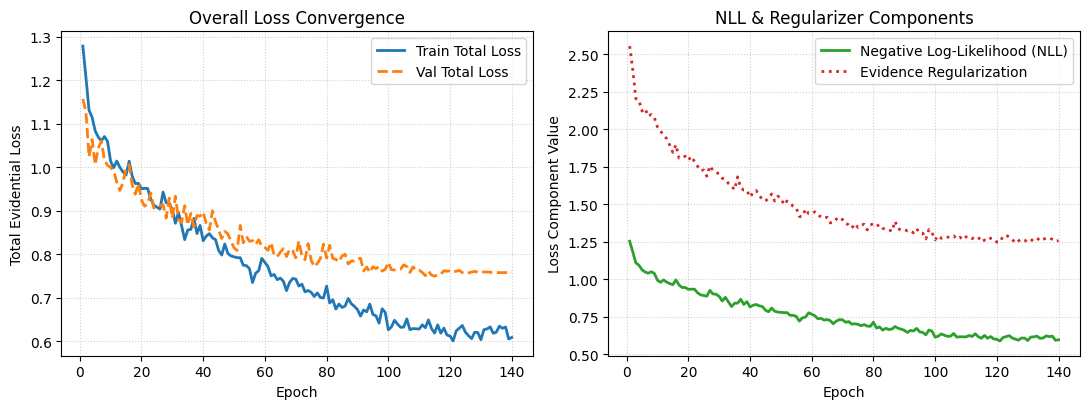

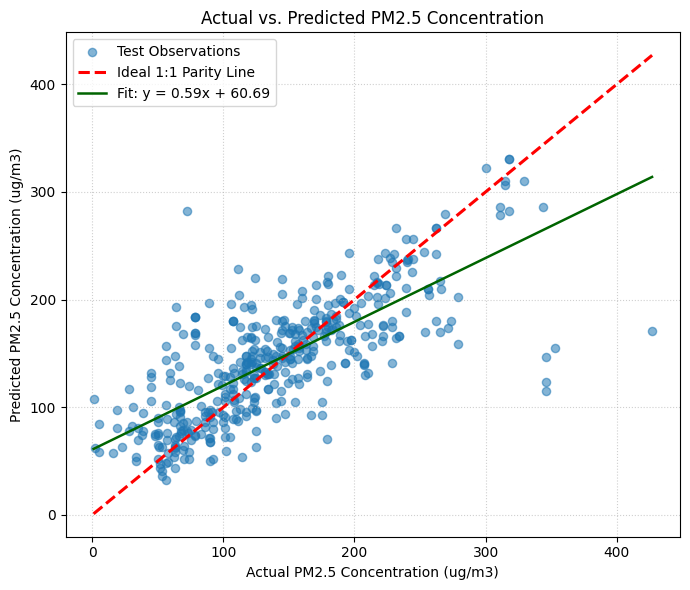

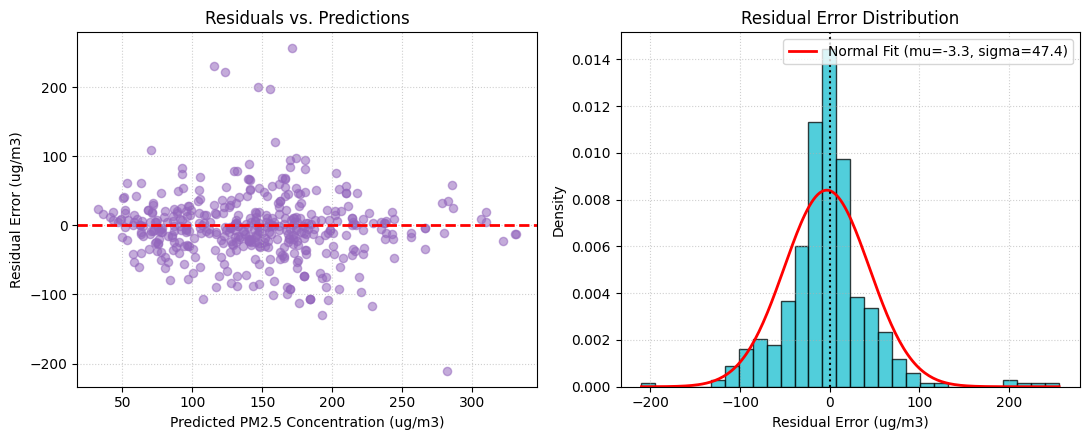

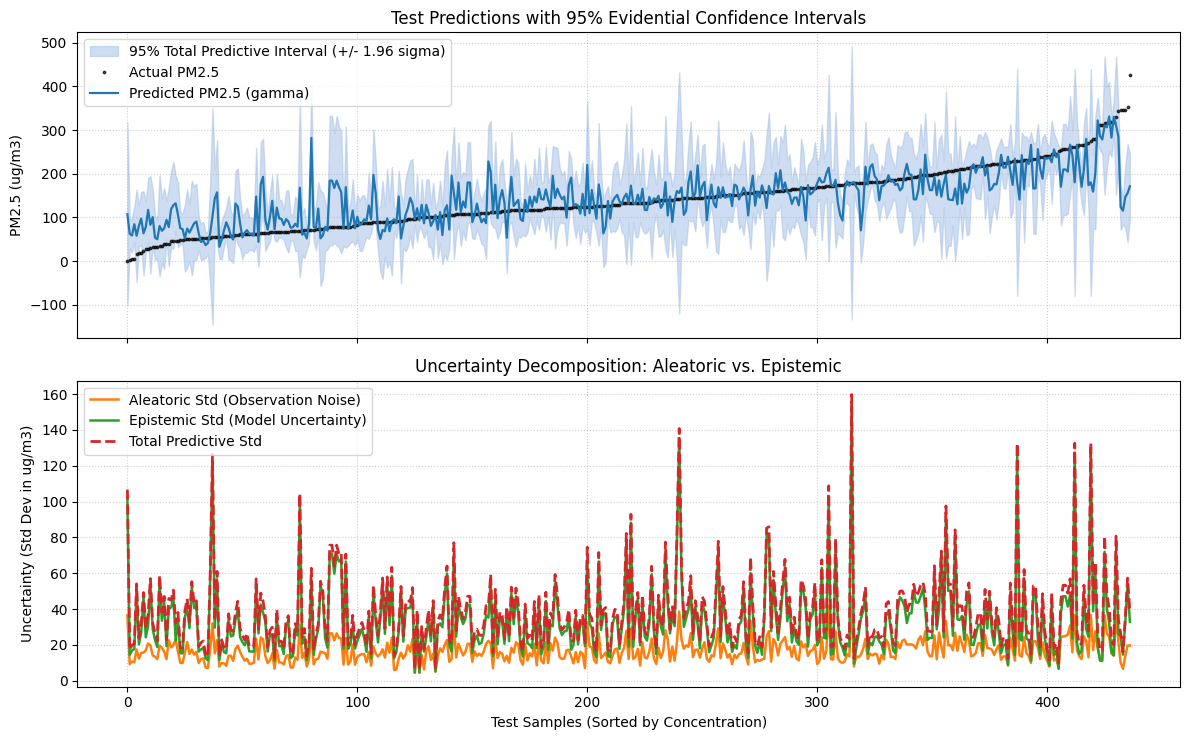

In [11]:
"""
Air Pollution Prediction Using Evidential Deep Regression (EDR)
---------------------------------------------------------------
Student Hall Ticket Number: 2303A51529
Model Assigned: Evidential Deep Regression (EDR)
Target Air Pollutant: PM2.5
Input Meteorological Features: RH, WD, SR, BP, AT

This script performs end-to-end model training, test evaluation,
and produces all 4 diagnostic plots from Section 3.5.
"""

import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# -------------------------------------------------------------
# 1. REPRODUCIBILITY & DATA PREPARATION
# -------------------------------------------------------------
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

excel_file = 'Data.xlsx'
if not os.path.exists(excel_file):
    raise FileNotFoundError(f"Dataset '{excel_file}' not found in current directory.")

print(f"[1/5] Loading data from {excel_file}...")
df_raw_path = "/content/Data.xlsx"
df_raw = pd.read_excel(df_raw_path)
features = ['RH', 'WD', 'SR', 'BP', 'AT']
target = 'PM2.5'
df = df_raw[[target] + features].copy()

# 80% Train, 20% Test Split
train_full, test = train_test_split(df, test_size=0.20, random_state=42)

# Impute missing Solar Radiation strictly with training median (zero data leakage)
sr_median = train_full['SR'].median()
train_full = train_full.copy()
test = test.copy()
train_full['SR'] = train_full['SR'].fillna(sr_median)
test['SR'] = test['SR'].fillna(sr_median)

# Split train_full into train (85%) and validation (15%) for checkpointing
train, val = train_test_split(train_full, test_size=0.15, random_state=42)

# -------------------------------------------------------------
# 2. STANDARDIZATION (Fitted strictly on training partition)
# -------------------------------------------------------------
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(train[features].values)
X_val = scaler_X.transform(val[features].values)
X_test = scaler_X.transform(test[features].values)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(train[[target]].values).flatten()
y_val = scaler_y.transform(val[[target]].values).flatten()
y_test = scaler_y.transform(test[[target]].values).flatten()
y_test_orig = test[target].values

# -------------------------------------------------------------
# 3. EVIDENTIAL DEEP REGRESSION ARCHITECTURE
# -------------------------------------------------------------
class EvidentialRegressionNet(nn.Module):
    """
    Evidential Neural Network parameterizing the Normal-Inverse-Gamma (NIG) distribution:
      - gamma: mean prediction (unrestricted real line)
      - v: virtual observation count (strictly v > 0)
      - alpha: shape parameter (strictly alpha > 1)
      - beta: scale parameter (strictly beta > 0)
    """
    def __init__(self, in_features=5, hidden_units=128, dropout_rate=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_units),
            nn.LayerNorm(hidden_units),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_units, hidden_units),
            nn.LayerNorm(hidden_units),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_units, 64),
            nn.LayerNorm(64),
            nn.SiLU()
        )
        self.out = nn.Linear(64, 4)

    def forward(self, x):
        h = self.net(x)
        raw = self.out(h)
        gamma = raw[:, 0]                          # Mean prediction
        v = F.softplus(raw[:, 1]) + 1e-4           # v > 0
        alpha = F.softplus(raw[:, 2]) + 1.0 + 1e-4 # alpha > 1
        beta = F.softplus(raw[:, 3]) + 1e-4        # beta > 0
        return gamma, v, alpha, beta

# -------------------------------------------------------------
# 4. EVIDENTIAL LOSS FUNCTION
# -------------------------------------------------------------
def evidential_loss(gamma, v, alpha, beta, y, reg_coeff=0.01):
    """
    Computes Student-t Negative Log-Likelihood + Evidence Regularization
    """
    diff = y - gamma
    error = torch.abs(diff)
    omega = 2.0 * beta * (1.0 + v)

    term1 = 0.5 * torch.log(math.pi / v)
    term2 = -alpha * torch.log(omega)
    term3 = (alpha + 0.5) * torch.log(v * (diff ** 2) + omega)
    term4 = torch.lgamma(alpha) - torch.lgamma(alpha + 0.5)

    nll = term1 + term2 + term3 + term4
    reg = error * (2.0 * v + alpha)
    return torch.mean(nll + reg_coeff * reg), torch.mean(nll), torch.mean(reg)

# -------------------------------------------------------------
# 5. MODEL TRAINING PIPELINE
# -------------------------------------------------------------
train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)),
    batch_size=64, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)),
    batch_size=64, shuffle=False
)

model = EvidentialRegressionNet(in_features=5, hidden_units=128, dropout_rate=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=140)

epochs = 140
best_loss = float('inf')
best_weights = None
history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'nll': [], 'reg': []}

print("[2/5] Training Evidential Deep Regression model (140 epochs)...")
for epoch in range(1, epochs + 1):
    model.train()
    t_loss, t_nll, t_reg, batches = 0.0, 0.0, 0.0, 0
    for bx, by in train_loader:
        optimizer.zero_grad()
        g, v, a, b = model(bx)
        loss, nll, reg = evidential_loss(g, v, a, b, by, reg_coeff=0.01)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        t_loss += loss.item()
        t_nll += nll.item()
        t_reg += reg.item()
        batches += 1
    scheduler.step()

    # Validation step
    model.eval()
    val_loss, count = 0.0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            g, v, a, b = model(bx)
            vl, _, _ = evidential_loss(g, v, a, b, by, reg_coeff=0.01)
            val_loss += vl.item()
            count += 1
    val_loss /= count

    history['epoch'].append(epoch)
    history['train_loss'].append(t_loss / batches)
    history['val_loss'].append(val_loss)
    history['nll'].append(t_nll / batches)
    history['reg'].append(t_reg / batches)

    if val_loss < best_loss:
        best_loss = val_loss
        best_weights = model.state_dict().copy()

    if epoch % 35 == 0 or epoch == 1:
        print(f"      Epoch {epoch:3d}/{epochs} | Train Loss: {t_loss/batches:.4f} | Val Loss: {val_loss:.4f}")

if best_weights is not None:
    model.load_state_dict(best_weights)
    print(f"      Loaded best model checkpoint (Validation Loss: {best_loss:.4f})")

# -------------------------------------------------------------
# 6. EVALUATION ON UNTOUCHED TEST SET
# -------------------------------------------------------------
print("\n[3/5] Evaluating on Untouched 20% Test Holdout...")
model.eval()
with torch.no_grad():
    g_s, v_t, a_t, b_s = model(torch.tensor(X_test, dtype=torch.float32))
    gamma_np = g_s.numpy()
    v_np = v_t.numpy()
    alpha_np = a_t.numpy()
    beta_np = b_s.numpy()

# Inverse Scaling
sigma_y = scaler_y.scale_[0]
mu_y = scaler_y.mean_[0]

y_pred = gamma_np * sigma_y + mu_y
beta_orig = beta_np * (sigma_y ** 2)

# Uncertainty Decomposition
aleatoric_var = beta_orig / (alpha_np - 1.0)
epistemic_var = beta_orig / (v_np * (alpha_np - 1.0))
total_var = aleatoric_var + epistemic_var

aleatoric_std = np.sqrt(aleatoric_var)
epistemic_std = np.sqrt(epistemic_var)
total_std = np.sqrt(total_var)

# Confidence intervals (95%)
ci_lower = y_pred - 1.96 * total_std
ci_upper = y_pred + 1.96 * total_std

# Standard Performance Metrics
mse = mean_squared_error(y_test_orig, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_orig, y_pred)
r2 = r2_score(y_test_orig, y_pred)
abs_pct_errors = np.abs((y_test_orig - y_pred) / y_test_orig) * 100
mape = np.mean(abs_pct_errors)
mdape = np.median(abs_pct_errors)
coverage = np.mean((y_test_orig >= ci_lower) & (y_test_orig <= ci_upper)) * 100

print("=" * 55)
print("TEST EVALUATION RESULTS (Untouched 20% Holdout):")
print("=" * 55)
print(f"Mean Squared Error (MSE)       : {mse:.2f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.2f} ug/m3")
print(f"Mean Absolute Error (MAE)      : {mae:.2f} ug/m3")
print(f"R-squared Score (R2)           : {r2:.4f}")
print(f"Mean Abs Percentage Error(MAPE): {mape:.2f}%")
print(f"Median Abs Percentage Err(MdAPE):{mdape:.2f}%")
print(f"95% Prediction Interval Cover. : {coverage:.2f}%")
print(f"Mean Aleatoric Std (sigma_ale) : {np.mean(aleatoric_std):.2f} ug/m3")
print(f"Mean Epistemic Std (sigma_epi) : {np.mean(epistemic_std):.2f} ug/m3")
print(f"Mean Total Predictive Std      : {np.mean(total_std):.2f} ug/m3")
print("=" * 55)

# -------------------------------------------------------------
# 7. SECTION 3.5: GRAPHICAL VISUALIZATIONS AND DIAGNOSTICS
# -------------------------------------------------------------
print("\n[4/5] Generating Section 3.5 Graphical Visualizations & Diagnostics...")
output_dir = 'outputs'
os.makedirs(output_dir, exist_ok=True)

# 1. Figure 1: Loss Convergence Curves
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(history['epoch'], history['train_loss'], label='Train Total Loss', color='#1f77b4', lw=2)
ax1.plot(history['epoch'], history['val_loss'], label='Val Total Loss', color='#ff7f0e', lw=2, linestyle='--')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Total Evidential Loss')
ax1.set_title('Overall Loss Convergence')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

ax2.plot(history['epoch'], history['nll'], label='Negative Log-Likelihood (NLL)', color='#2ca02c', lw=2)
ax2.plot(history['epoch'], history['reg'], label='Evidence Regularization', color='#d62728', lw=2, linestyle=':')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss Component Value')
ax2.set_title('NLL & Regularizer Components')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()
fig1.tight_layout()
fig1_path = os.path.join(output_dir, 'figure1_loss_convergence.png')
fig1.savefig(fig1_path, dpi=300)
print(f"      Saved: {fig1_path}")

# 2. Figure 2: Actual vs. Predicted Parity Plot
fig2, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test_orig, y_pred, alpha=0.55, color='#1f77b4', s=35, label='Test Observations')
min_val = min(y_test_orig.min(), y_pred.min())
max_val = max(y_test_orig.max(), y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.2, label='Ideal 1:1 Parity Line')
z = np.polyfit(y_test_orig, y_pred, 1)
p = np.poly1d(z)
ax.plot(np.linspace(min_val, max_val, 100), p(np.linspace(min_val, max_val, 100)),
        color='darkgreen', linestyle='-', lw=1.8, label=f'Fit: y = {z[0]:.2f}x + {z[1]:.2f}')
ax.set_xlabel('Actual PM2.5 Concentration (ug/m3)')
ax.set_ylabel('Predicted PM2.5 Concentration (ug/m3)')
ax.set_title('Actual vs. Predicted PM2.5 Concentration')
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)
fig2.tight_layout()
fig2_path = os.path.join(output_dir, 'figure2_actual_vs_predicted.png')
fig2.savefig(fig2_path, dpi=300)
print(f"      Saved: {fig2_path}")

# 3. Figure 3: Residuals & Distribution Histogram
fig3, (ax_r, ax_h) = plt.subplots(1, 2, figsize=(11, 4.5))
res = y_test_orig - y_pred
ax_r.scatter(y_pred, res, alpha=0.55, color='#9467bd', s=35)
ax_r.axhline(0, color='red', linestyle='--', lw=2)
ax_r.set_xlabel('Predicted PM2.5 Concentration (ug/m3)')
ax_r.set_ylabel('Residual Error (ug/m3)')
ax_r.set_title('Residuals vs. Predictions')
ax_r.grid(True, linestyle=':', alpha=0.6)

ax_h.hist(res, bins=30, color='#17becf', edgecolor='black', alpha=0.75, density=True)
res_mean, res_std = res.mean(), res.std()
x_grid = np.linspace(res.min(), res.max(), 200)
norm_pdf = (1.0 / (res_std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_grid - res_mean) / res_std) ** 2)
ax_h.plot(x_grid, norm_pdf, 'r-', lw=2, label=f'Normal Fit (mu={res_mean:.1f}, sigma={res_std:.1f})')
ax_h.axvline(0, color='black', linestyle=':', lw=1.5)
ax_h.set_xlabel('Residual Error (ug/m3)')
ax_h.set_ylabel('Density')
ax_h.set_title('Residual Error Distribution')
ax_h.legend()
ax_h.grid(True, linestyle=':', alpha=0.6)
fig3.tight_layout()
fig3_path = os.path.join(output_dir, 'figure3_residuals_distribution.png')
fig3.savefig(fig3_path, dpi=300)
print(f"      Saved: {fig3_path}")

# 4. Figure 4: Uncertainty Quantification & Decomposition
fig4, (ax_ci, ax_dec) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
sort_idx = np.argsort(y_test_orig)
sorted_actual = y_test_orig[sort_idx]
sorted_pred = y_pred[sort_idx]
sorted_ci_low = ci_lower[sort_idx]
sorted_ci_up = ci_upper[sort_idx]
sorted_ale = aleatoric_std[sort_idx]
sorted_epi = epistemic_std[sort_idx]
sorted_tot = total_std[sort_idx]
s_range = np.arange(len(sorted_actual))

# 95% Confidence Interval Coverage
ax_ci.fill_between(s_range, sorted_ci_low, sorted_ci_up, color='#aec7e8', alpha=0.6,
                   label='95% Total Predictive Interval (+/- 1.96 sigma)')
ax_ci.plot(s_range, sorted_actual, 'k.', markersize=3.5, alpha=0.7, label='Actual PM2.5')
ax_ci.plot(s_range, sorted_pred, color='#1f77b4', lw=1.6, label='Predicted PM2.5 (gamma)')
ax_ci.set_ylabel('PM2.5 (ug/m3)')
ax_ci.set_title('Test Predictions with 95% Evidential Confidence Intervals')
ax_ci.legend(loc='upper left')
ax_ci.grid(True, linestyle=':', alpha=0.6)

# Uncertainty Decomposition
ax_dec.plot(s_range, sorted_ale, color='#ff7f0e', lw=1.8, label='Aleatoric Std (Observation Noise)')
ax_dec.plot(s_range, sorted_epi, color='#2ca02c', lw=1.8, label='Epistemic Std (Model Uncertainty)')
ax_dec.plot(s_range, sorted_tot, color='#d62728', lw=2.0, linestyle='--', label='Total Predictive Std')
ax_dec.set_xlabel('Test Samples (Sorted by Concentration)')
ax_dec.set_ylabel('Uncertainty (Std Dev in ug/m3)')
ax_dec.set_title('Uncertainty Decomposition: Aleatoric vs. Epistemic')
ax_dec.legend(loc='upper left')
ax_dec.grid(True, linestyle=':', alpha=0.6)
fig4.tight_layout()
fig4_path = os.path.join(output_dir, 'figure4_uncertainty_decomposition.png')
fig4.savefig(fig4_path, dpi=300)
print(f"      Saved: {fig4_path}")

print(f"\n[5/5] All Section 3.5 plots generated and saved successfully in '{output_dir}/'!")
print("      Displaying all 4 graphical diagnostic figures on screen...")
plt.show()

if __name__ == '__main__':
    pass